In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report
from sklearn import metrics
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

In [1]:
import pandas as pd
from sklearn import preprocessing

# 1. Definimos las columnas reales de la base de drugs
col_names = ["Age", "Sex", "BP", "Cholesterol", "Na_to_K", "Drug"]

# 2. Cargamos la base (asumiendo que el archivo se llama drugs.csv)
df = pd.read_csv("drugs.csv") 

# 3. Creamos el codificador
le = preprocessing.LabelEncoder()

# 4. Seleccionamos las variables cualitativas (texto) que queremos convertir
columnas_a_codificar = ["Sex", "BP", "Cholesterol", "Drug"]

# 5. Aplicamos LabelEncoder a cada columna
for col in columnas_a_codificar:
    df[col] = le.fit_transform(df[col])

# Mostramos el resultado
df.head()

,Age,Sex,BP,Cholesterol,Na_to_K,Drug
0,23,0,0,0,25.355,4
1,47,1,1,0,13.093,2
2,47,1,1,0,10.114,2
3,28,0,2,0,7.798,3
4,61,0,1,0,18.043,4


In [4]:
# Selección de las caracteristicas
feature_cols = ["Age", "Sex", "BP", "Cholesterol", "Na_to_K"]
X = df[feature_cols]
y = df.Drug

In [7]:
from sklearn.model_selection import train_test_split

# Creación de las bases de entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 1)

In [8]:
# sag: Stochastic Average Gradient
# newton-cg: Newton
# liblinear: Library for large linear classification (Algoritmo Coordiante Descent)
# saga: Variante del método sag
# lbfgs: Limited-memory Broyden–Fletcher–Goldfarb–Shanno Algorithm

#Regresión logística con Solucionador (Solver): sag

In [12]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report

model = LogisticRegression(solver="sag")
clf = model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Intercepto (Beta0): ", clf.intercept_)
print("Pesos (Betas): ", clf.coef_)
print("----------------------------------------------------------")
score = model.score(X_test, y_test)
print("Precisión global: ", score)
print("------------------------------------------------")
print(classification_report(y_test, y_pred))

Intercepto (Beta0):  [ 0.25295864 -0.08249796  0.08590658  0.28749494 -0.5438622 ]
Pesos (Betas):  [[-0.02648365  0.16163908 -0.64191448  0.05710529  0.0999963 ]
 [ 0.0717218  -0.03977628 -0.62925319 -0.01165771 -0.2771776 ]
 [-0.00369131  0.01410225  0.14676117 -0.27471721 -0.01626131]
 [ 0.00980669 -0.05118792  1.29022145  0.42443215 -0.11592328]
 [-0.05135353 -0.08477713 -0.16581495 -0.19516252  0.30936589]]
----------------------------------------------------------
Precisión global:  0.7
------------------------------------------------
              precision    recall  f1-score   support

           0       0.00      0.00      0.00         4
           1       0.33      1.00      0.50         2
           2       0.00      0.00      0.00         4
           3       0.79      0.85      0.81        13
           4       0.75      0.88      0.81        17

    accuracy                           0.70        40
   macro avg       0.37      0.55      0.43        40
weighted avg       0

/opt/conda/envs/anaconda-2022.05-py39/lib/python3.9/site-packages/sklearn/linear_model/_sag.py:352: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/opt/conda/envs/anaconda-2022.05-py39/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1318: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/opt/conda/envs/anaconda-2022.05-py39/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1318: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/opt/conda/envs/anaconda-2022.05-py39/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1318: UndefinedMetricW

In [ ]:
#Regresión logística con Solucionador (Solver): newton-cg

In [13]:
model = LogisticRegression(solver="newton-cg")
clf = model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Intercepto (Beta0): ", clf.intercept_)
print("Pesos (Betas): ", clf.coef_)
print("----------------------------------------------------------")
score = model.score(X_test, y_test)
print("Precisión global: ", score)
print("------------------------------------------------")
print(classification_report(y_test, y_pred))

Intercepto (Beta0):  [ 14.92967819   0.8790824   10.25640506   6.24448934 -32.30965499]
Pesos (Betas):  [[-8.96130627e-02  3.54951175e-02 -2.31758767e+00 -4.79054574e-01
  -6.88035007e-01]
 [ 1.24913439e-01 -6.72385113e-02 -1.72769746e+00  8.90228247e-02
  -4.39121719e-01]
 [-2.62169961e-02 -8.10886935e-02  5.55538904e-01 -1.49469687e+00
  -6.08740693e-01]
 [-6.10368281e-03 -3.06445877e-01  3.06999789e+00  1.74859710e+00
  -5.84056242e-01]
 [-2.97941835e-03  4.19277967e-01  4.19748341e-01  1.36131520e-01
   2.31995381e+00]]
----------------------------------------------------------
Precisión global:  0.95
------------------------------------------------
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         4
           1       0.50      1.00      0.67         2
           2       1.00      0.50      0.67         4
           3       1.00      1.00      1.00        13
           4       1.00      1.00      1.00        17

    accuracy

In [ ]:
#Regresión logística con Solucionador (Solver): liblinear

In [14]:
model = LogisticRegression(solver="liblinear")
clf = model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Intercepto (Beta0): ", clf.intercept_)
print("Pesos (Betas): ", clf.coef_)
print("----------------------------------------------------------")
score = model.score(X_test, y_test)
print("Precisión global: ", score)
print("------------------------------------------------")
print(classification_report(y_test, y_pred))

Intercepto (Beta0):  [ 2.40746561 -0.69169247  0.59552877  0.49274606 -4.53305879]
Pesos (Betas):  [[-2.92140699e-02  4.44045986e-01 -2.27567481e+00 -3.95479579e-01
  -1.64992579e-01]
 [ 1.06714256e-01 -4.68494848e-01 -2.51665437e+00 -2.91727058e-01
  -4.28052683e-01]
 [-2.39661120e-03  5.01768312e-03 -5.76612086e-02 -1.77734484e+00
  -1.83201944e-01]
 [ 9.67804662e-03 -5.71764844e-01  3.03029788e+00  2.17470282e+00
  -4.65843053e-01]
 [-4.05475255e-02  5.57354660e-02 -2.72511077e-01 -4.43385659e-01
   4.48981390e-01]]
----------------------------------------------------------
Precisión global:  0.825
------------------------------------------------
              precision    recall  f1-score   support

           0       1.00      0.75      0.86         4
           1       0.40      1.00      0.57         2
           2       0.00      0.00      0.00         4
           3       0.81      1.00      0.90        13
           4       0.94      0.88      0.91        17

    accuracy    

/opt/conda/envs/anaconda-2022.05-py39/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1318: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/opt/conda/envs/anaconda-2022.05-py39/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1318: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/opt/conda/envs/anaconda-2022.05-py39/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1318: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start,

#Regresión logística con Solucionador (Solver): saga

In [15]:
model = LogisticRegression(solver="saga")
clf = model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Intercepto (Beta0): ", clf.intercept_)
print("Pesos (Betas): ", clf.coef_)
print("----------------------------------------------------------")
score = model.score(X_test, y_test)
print("Precisión global: ", score)
print("------------------------------------------------")
print(classification_report(y_test, y_pred))

Intercepto (Beta0):  [ 0.12844724 -0.05356778  0.04151979  0.17753684 -0.29393609]
Pesos (Betas):  [[-0.02420074  0.09441309 -0.38649633  0.03881764  0.08718769]
 [ 0.06550987 -0.02071572 -0.38584656 -0.001808   -0.26874265]
 [-0.00368341  0.00631771  0.0686455  -0.14845426 -0.01997403]
 [ 0.01341293 -0.0254672   0.85569489  0.22822283 -0.08044568]
 [-0.05103865 -0.05454788 -0.1519975  -0.1167782   0.28197467]]
----------------------------------------------------------
Precisión global:  0.725
------------------------------------------------
              precision    recall  f1-score   support

           0       0.00      0.00      0.00         4
           1       0.33      1.00      0.50         2
           2       0.00      0.00      0.00         4
           3       0.85      0.85      0.85        13
           4       0.76      0.94      0.84        17

    accuracy                           0.73        40
   macro avg       0.39      0.56      0.44        40
weighted avg      

/opt/conda/envs/anaconda-2022.05-py39/lib/python3.9/site-packages/sklearn/linear_model/_sag.py:352: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/opt/conda/envs/anaconda-2022.05-py39/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1318: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/opt/conda/envs/anaconda-2022.05-py39/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1318: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/opt/conda/envs/anaconda-2022.05-py39/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1318: UndefinedMetricW

#Regresión logística con Solucionador (Solver):lbfgs

In [16]:
model = LogisticRegression(solver="lbfgs")
clf = model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Intercepto (Beta0): ", clf.intercept_)
print("Pesos (Betas): ", clf.coef_)
print("----------------------------------------------------------")
score = model.score(X_test, y_test)
print("Precisión global: ", score)
print("------------------------------------------------")
print(classification_report(y_test, y_pred))

Intercepto (Beta0):  [ 2.30436866 -0.56810706  1.04509258  1.46243485 -4.24378904]
Pesos (Betas):  [[-0.03541414  0.69135439 -2.91421475 -0.30423277  0.06592299]
 [ 0.11056347 -0.45760596 -2.75015814 -0.30721703 -0.27445624]
 [-0.02041118  0.13566284  1.17497615 -1.75743252  0.00561669]
 [-0.01219046 -0.55081728  4.02627837  2.83701184 -0.37098391]
 [-0.04254768  0.18140602  0.46311836 -0.46812952  0.57390047]]
----------------------------------------------------------
Precisión global:  0.85
------------------------------------------------
              precision    recall  f1-score   support

           0       1.00      0.75      0.86         4
           1       0.50      1.00      0.67         2
           2       1.00      0.25      0.40         4
           3       0.81      1.00      0.90        13
           4       0.94      0.88      0.91        17

    accuracy                           0.85        40
   macro avg       0.85      0.78      0.75        40
weighted avg       

/opt/conda/envs/anaconda-2022.05-py39/lib/python3.9/site-packages/sklearn/linear_model/_logistic.py:814: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


# Nos quedamos con el solucionador Newton-cg ya que tiene un F1 score del 95%, el más alto entre cada solucionador.

In [17]:
# Predicción de probabilidades para casos particulares
y_pred_probs = clf.predict_proba(X_test)[:,1]
y_pred_probs[0:5]

array([3.37396551e-05, 3.37817359e-04, 2.15008595e-04, 1.07058806e-03,
       1.23543610e-11])

In [18]:
y_test[0:5]

58     3
40     4
34     3
102    2
184    4
Name: Drug, dtype: int64

In [19]:
y_test = y_test.to_numpy()
y_test[0:5]

y_test = [int(numeric_string) for numeric_string in y_test]
y_test[0:5]

[3, 4, 3, 2, 4]

In [20]:
import numpy as np
y_pred_probs = np.round(y_pred_probs,0)
y_pred_probs[0:5]

array([0., 0., 0., 0., 0.])

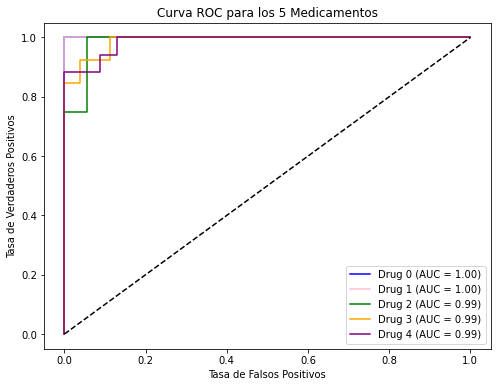

In [25]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize

# 1. Obtenemos TODAS las probabilidades del modelo (Matriz de N x 5)
y_pred_probs = model.predict_proba(X_test)

# 2. Binarizamos y_test (convierte 0,1,2,3,4 en columnas de 0s y 1s)
y_test_bin = label_binarize(y_test, classes=[0, 1, 2, 3, 4])
n_classes = y_test_bin.shape[1]

# 3. Calculamos las curvas para cada medicamento
fpr = dict()
tpr = dict()
roc_auc = dict()

for i in range(n_classes):
    fpr[i], tpr[i], _ = roc_curve(y_test_bin[:, i], y_pred_probs[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# 4. Graficamos 
plt.figure(figsize=(8, 6))
colores = ['blue', 'pink', 'green', 'orange', 'purple']
nombres_medicamentos = ['Drug 0', 'Drug 1', 'Drug 2', 'Drug 3', 'Drug 4']

for i in range(n_classes):
    plt.plot(fpr[i], tpr[i], color=colores[i], label=f'{nombres_medicamentos[i]} (AUC = {roc_auc[i]:.2f})')

# Línea diagonal
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('Tasa de Falsos Positivos')
plt.ylabel('Tasa de Verdaderos Positivos')
plt.title('Curva ROC para los 5 Medicamentos')
plt.legend(loc="lower right")
plt.show()

PREGUNTA FINAL

¿Qué tan eficaz es el algoritmo predictivo escogido? Explique a detalle
comentando sobre los indicadores obtenidos mediante el reporte de clasificación
correspondiente y la curva ROC

El algoritmo de regresión logística (con el método newton-cg) escogido es altamente eficaz. El reporte de clasificación muestra un  F1-score del 95%, lo que indica que el modelo predice correctamente los 5 medicamentos con muy pocos errores. Esto se confirma con la curva ROC, donde el AUC fue de 0.99 y 1.00 para todas las clases. Un valor tan cercano a 1 significa que el modelo distingue casi a la perfección entre un medicamento y otro, con una tasa de falsos positivos prácticamente nula."